# Price forecasts: model performance

Four models of the GB half-hourly wholesale price, issued daily at 10:00 London time for the rest of today (Block A) and all of tomorrow (Block B): **naive weekly** (same local time 7 days ago), **naive daily** (yesterday on Tue–Fri, 7 days ago on Sat–Mon), **LEAR** (lasso on recent prices) and **LEAR + exog** (`lear_x`: LEAR plus day-ahead forecasts of demand, wind and embedded wind/solar).
Backtest issues 2025-10-01 to 2026-09-30 with weekly recalibration; targets without an actual price are excluded. All prices in £/MWh.

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
warnings.filterwarnings("ignore")
%matplotlib inline

from v2g.forecast import plots

plots.apply_style()
data = plots.load_backtest()
print(plots.describe(data))

110,712 scored rows for 4 models over 365 daily issues (2025-10-01 to 2026-09-30, targets with a known actual price).


### Summary

In [2]:
plots.summary_table(data)

,MAE (£/MWh),RMSE (£/MWh),rMAE vs naive weekly,Pinball loss,P10–P90 coverage (%),rows
model,,,,,,
naive weekly,29.40,45.44,1.000,10.59,78.1,27678
naive daily,27.88,43.94,0.949,10.17,78.4,27678
LEAR,20.16,30.40,0.686,6.90,76.1,27678
LEAR + exog (lear_x),17.22,25.80,0.586,5.81,76.4,27678


`lear_x` has the lowest error on every metric: MAE 17.22 £/MWh against 20.16 for LEAR and 27.88 for naive daily, and an rMAE of 0.586, i.e. 41% less error than the weekly naive. P10–P90 coverage is 76–78% for all four models against the nominal 80%.

### Headline accuracy

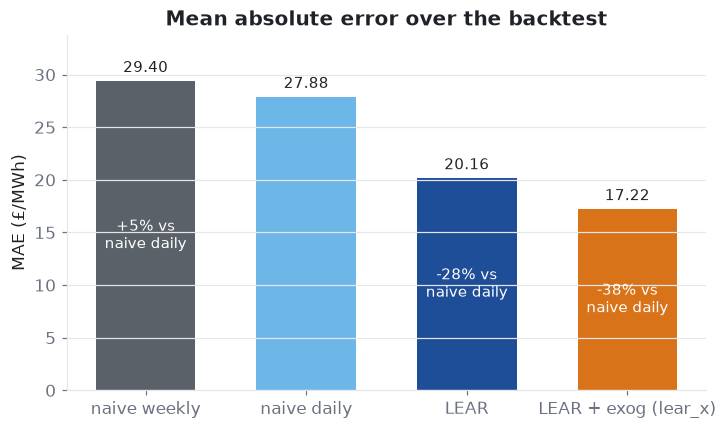

In [3]:
fig = plots.plot_mae_bars(data)
plots.save(fig, "01_02_mae_bars");

Adding the exogenous forecasts cuts MAE from 20.16 to 17.22 £/MWh (−15%). Relative to naive daily the reduction is 38%, of which LEAR alone delivers 28 points.

### Rest of today versus tomorrow

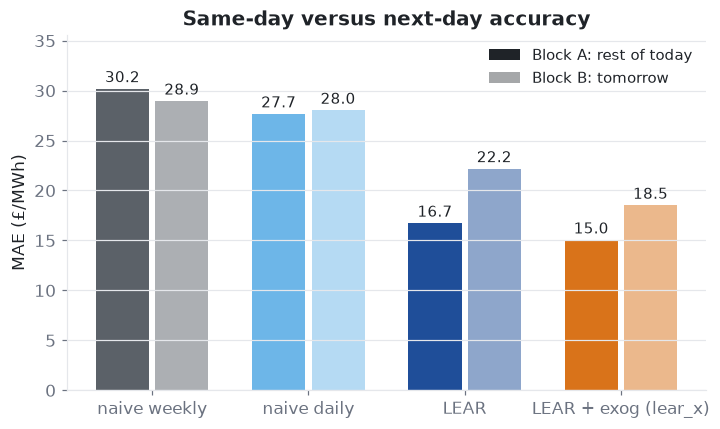

In [4]:
fig = plots.plot_block_mae(data)
plots.save(fig, "01_03_block_mae");

The exogenous gain is largest for tomorrow: Block B MAE falls from 22.17 to 18.51 £/MWh (−17%), Block A from 16.71 to 15.03 (−10%). The naive models find both blocks equally hard at about 28.

### Errors by time of day

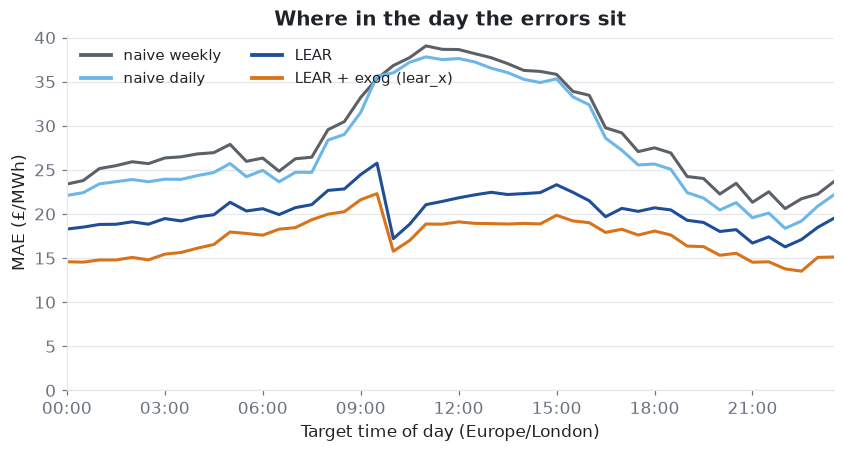

In [5]:
fig = plots.plot_mae_by_time_of_day(data)
plots.save(fig, "01_04_mae_time_of_day");

Errors peak on the morning ramp, not the evening: naive daily reaches 37.8 £/MWh at 11:00 and `lear_x` 22.3 at 09:30, against 13.5 for `lear_x` at 22:30. Over the evening peak (16:00–19:30) `lear_x` averages 17.6, barely above its 02:00–05:30 level of 16.2.

### Month by month

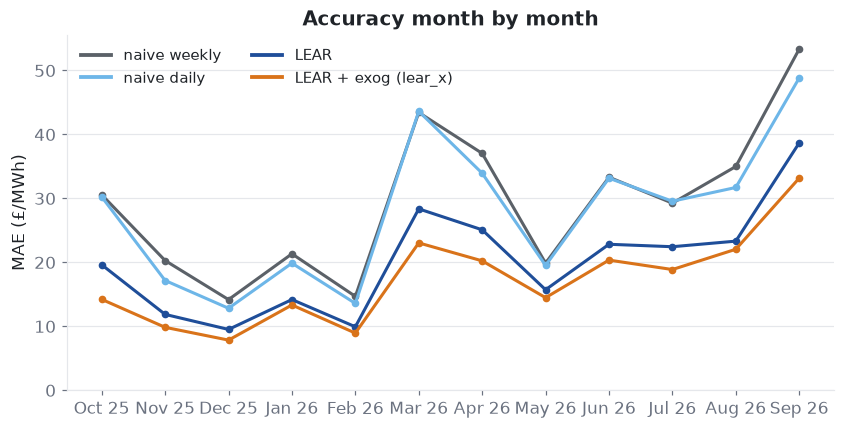

In [6]:
fig = plots.plot_mae_by_month(data)
plots.save(fig, "01_05_mae_month");

`lear_x` is the most accurate model in every month. Errors track volatility, from 7.8 £/MWh in December 2025 to 33.2 in September 2026 (naive daily 48.8); its edge over LEAR is widest in October 2025 (14.2 vs 19.6, −28%) and narrowest in August 2026 (22.0 vs 23.3).

### Negative prices and spikes

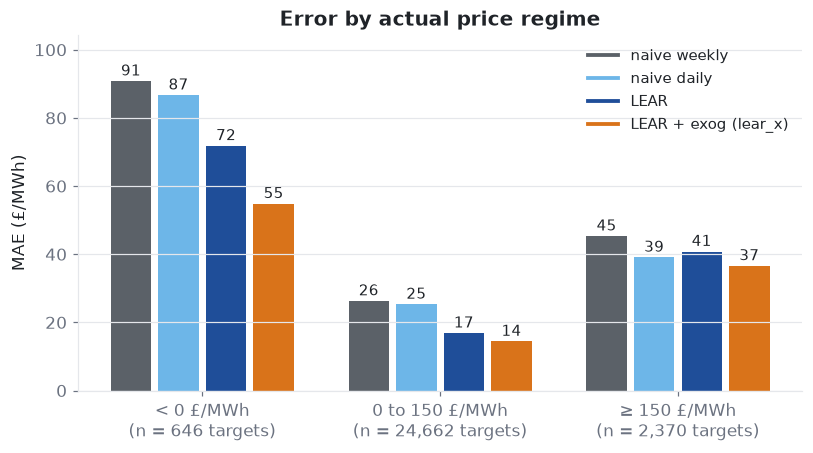

In [7]:
fig = plots.plot_mae_by_price_regime(data)
plots.save(fig, "01_06_mae_regime");

Negative prices (646 targets) are the hardest regime, and where the exogenous forecasts help most: `lear_x` MAE 54.8 £/MWh against 71.8 for LEAR and 86.7 for naive daily. On spikes above 150 £/MWh (2,370 targets) the gap narrows to 36.6 vs 40.8; in the ordinary 0–150 range `lear_x` reaches 14.4.

### Calibration of the P10–P90 band

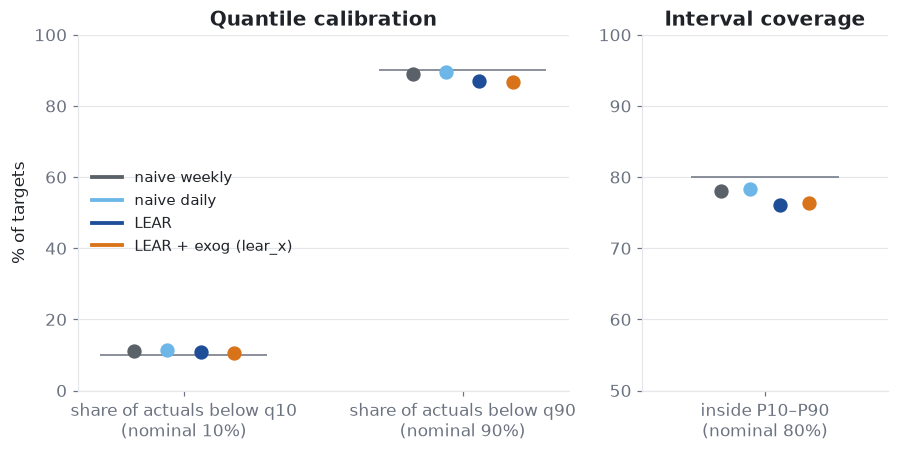

In [8]:
fig = plots.plot_calibration(data)
plots.save(fig, "01_07_calibration");

The lower tail is well calibrated (10.5–11.3% of actuals fall below q10 against a nominal 10%), the upper tail is not: only 86.9% of actuals fall below `lear_x`'s q90 against a nominal 90%, so coverage lands at 76.4% instead of 80%. Prices overshoot the band more often than they undershoot it.

### Are the differences significant? Diebold–Mariano

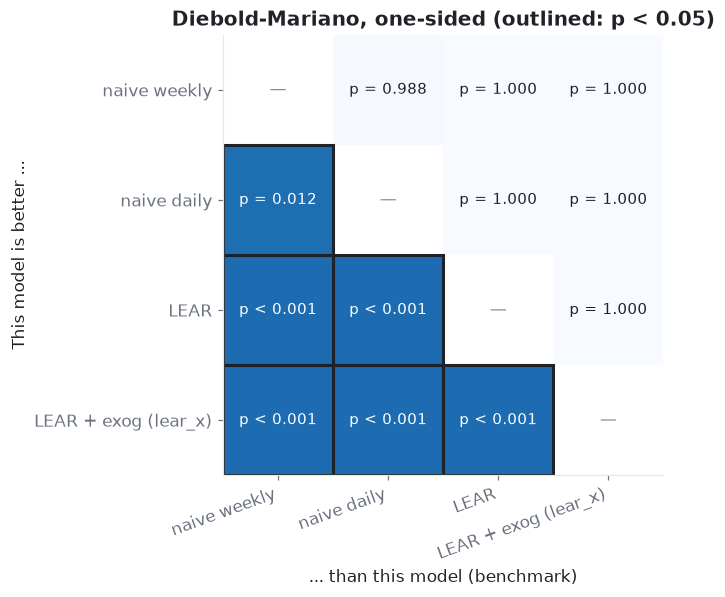

In [9]:
fig = plots.plot_dm_matrix(data)
plots.save(fig, "01_08_dm_matrix");

Every step down the ladder is significant: `lear_x` beats all three alternatives and LEAR beats both naive models at p < 0.001 over 365 issues; naive daily beats naive weekly at p = 0.012.

## Conclusions

- `lear_x` is the model to use: MAE 17.22 £/MWh, 15% below LEAR and 38% below naive daily, significant at p < 0.001 against every alternative, and best in all 12 months.
- The exogenous day-ahead forecasts earn their keep where past prices fail: tomorrow's prices (Block B −17%) and negative-price periods (−24% vs LEAR).
- Point forecasts are strong, the bands are slightly too narrow on the upside: 13% of actuals exceed q90 against the nominal 10%, giving 76% coverage instead of 80%.